# Lecture 26 notebook: trend speeds that work across the board

This notebook replays Lecture 26. Every figure and number of the lecture comes from a script in `scripts/`, next to this notebook; each runs in a fresh process. The data are free: the daily prices of Lecture 25's 116 ETFs from Yahoo Finance and the 3-month Treasury bill rate from FRED (series DTB3), downloaded once into `data/portfolio` (not committed).

By default the notebook downloads what is missing, builds the 36 daily trend streams of every market if they are not there yet (about ten minutes), redraws every figure of the lecture as `figures/nb_*.png` from the shipped results, and checks the lecture's examples by hand against the library. `RUN_ALL` also reruns the yearly choice of speeds with 500 random halves and the out-of-sample tests (about an hour) and compares them with the shipped numbers. Recomputed results never overwrite the shipped ones.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings and data | §3 |
| 1 | The key chart | §1 |
| 2 | The streams, with hand checks: signals, positions, returns over cash, costs | §3 |
| 3 | The rule, with one random split by hand; markets that disagree | §4 |
| 4 | The areas and what the rule holds | §5 |
| 5 | Super-long speeds in US equity | §6 |
| 6 | Out of sample | §7 |
| 7 | A test of your own | |

## 0. Settings and data

In [1]:
import json, os, shutil, subprocess, sys, time
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS)]
import l26 as L
RUN_ALL = False                                                            # True: also rerun the yearly choice of speeds and the tests (about an hour)

SHIPPED = HERE / "results"; WORK = L.L25.DATA / "l26_results"             # recomputed results go to WORK, never over the shipped ones
if not WORK.exists(): shutil.copytree(SHIPPED, WORK)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
print("data:", L.L25.DATA, "| streams:", L.OUT / "streams", "| shipped results:", SHIPPED, "| recomputed results:", WORK)


def run(script, *args, show=False):
    "Run a script of this lecture or of Lecture 25 in a fresh process; figures as nb_*, results to WORK."
    t0 = time.time(); path = SCRIPTS / script if (SCRIPTS / script).exists() else L.REPO / "lectures" / "25-choosing-the-markets" / "scripts" / script
    env = {**os.environ, "PORTFOLIO_DATA": str(L.L25.DATA), "L26_RESULTS": str(WORK), "L26_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, str(path), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)


def result(name, where=None):
    return json.loads(((where or WORK) / name).read_text(encoding="utf-8"))


stream = lambda t: pd.read_parquet(L.OUT / "streams" / f"{t}.parquet")      # gross returns g_* and trades t_* of a market's 36 streams

data: C:\Users\maxgn\New Trading Models\data\raw\portfolio | streams: C:\Users\maxgn\New Trading Models\data\raw\portfolio\l26\streams | shipped results: C:\Users\maxgn\New Trading Models\systematic-trading-notes\lectures\26-trend-speeds-by-asset-class\results | recomputed results: C:\Users\maxgn\New Trading Models\data\raw\portfolio\l26_results


**The data.** The ETF prices come from Lecture 25's download script, the bill rate from FRED. The streams are built once: for each market, the three rules at twelve speeds on its price over cash, sized by six-month volatility and traded a tenth of the way to the target each day (§3).

In [2]:
if not L.L25.RAW.exists(): run("l25_fetch.py", show=True)
if not L.RATE.exists(): run("l26_fetch_rate.py", show=True)
if len(list((L.OUT / "streams").glob("*.parquet"))) < 100: run("l26_streams.py", show=True)
close, high, low, dv, rf = L.load_daily()
print(f"{close.shape[1]} ETFs, {close.index.min().date()} to {close.index.max().date()}; bill rate on the last day {rf.iloc[-1] * 252:.2%} a year")
print("speeds:", L.SPEEDS, "| rules:", L.RULES, "| cost", L.COST_BP, "bp | volatility span", L.VOL_SPAN, "days")

116 ETFs, 1993-01-29 to 2026-11-12; bill rate on the last day 4.12% a year
speeds: (11, 17, 23, 31, 43, 61, 89, 127, 179, 251, 359, 503) | rules: ('ewma', 'breakout', 'return') | cost 5.0 bp | volatility span 126 days


**Running everything.** With `RUN_ALL` the cell below reruns the long steps: the choice of speeds at every year end 2012-2025 with 500 random halves for each version (§4, §7), then the out-of-sample tests with 2,000 bootstrap resamples (§7). Otherwise the shipped results are used.

In [3]:
if RUN_ALL:
    run("l26_select.py"); run("l26_tests.py")

## 1. The key chart

Left: the share of 500 random halves in which each stream works on both halves, at the end-2025 review. Right: the Sharpe ratio after costs out of sample, per class and in total.

l26_key_chart.py : 3 s


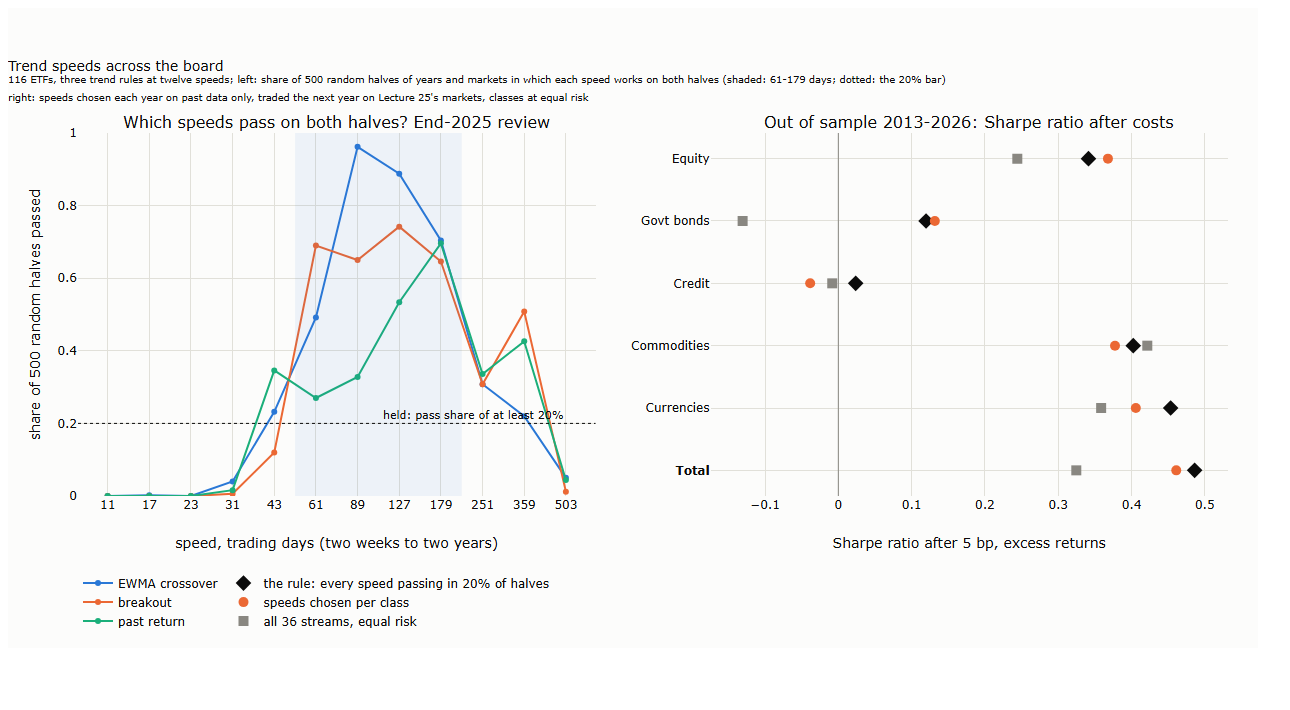

In [4]:
run("l26_key_chart.py")
pictures("26_key")

## 2. The streams

### 2.1 Hand checks: the signals

The EWMA crossover of SPY at 61 days on 31 March 2020: the exponential averages of the log price over cash written out as weighted sums (weights $`(1-\alpha)^i`$ with $`\alpha = 2/(\text{span}+1)`$, as pandas computes them), then their difference's sign; and the sign of the 61-day return. Both against `l26.signals`.

In [5]:
t, h, day = "SPY", 61, pd.Timestamp("2020-03-31")
c = close[t].dropna(); x, xh, xl = L.excess(c, high[t].reindex(c.index), low[t].reindex(c.index), rf); lp = np.log(x); j = lp.index.get_loc(day)
def ew(span):
    a = 2 / (span + 1); w = (1 - a) ** np.arange(j + 1)[::-1]; return (w * lp.iloc[: j + 1].to_numpy()).sum() / w.sum()
sig = L.signals(x.to_frame("x"), xh.to_frame("x"), xl.to_frame("x"), h)
print(f"fast average (span {h // 4}) {ew(h // 4):.6f}, slow (span {h}) {ew(h):.6f}: sign by hand {np.sign(ew(h // 4) - ew(h)):+.0f}, library {sig['ewma']['x'].loc[day]:+.0f}")
print(f"{h}-day return {x.iloc[j] / x.iloc[j - h] - 1:+.2%}: sign by hand {np.sign(x.iloc[j] / x.iloc[j - h] - 1):+.0f}, library {sig['return']['x'].loc[day]:+.0f}")

fast average (span 15) 4.808391, slow (span 61) 4.922638: sign by hand -1, library -1
61-day return -20.40%: sign by hand -1, library -1


### 2.2 Hand checks: a stream, step by step

IEF's EWMA crossover at 89 days, rebuilt from its parts: volatility over six months, the target position 10% / volatility times the sign, a tenth of the gap closed each day, the position held over the next day earning that day's return over cash, and 5 bp on the value traded. Then the account identity of §3.2 with two made-up positions.

In [6]:
t, h = "IEF", 89
c = close[t].dropna(); x, xh, xl = L.excess(c, high[t].reindex(c.index), low[t].reindex(c.index), rf); r = x.pct_change()
vol = np.sqrt((r ** 2).ewm(span=126, min_periods=60).mean() * 252)
s = L.signals(x.to_frame("x"), xh.to_frame("x"), xl.to_frame("x"), h)["ewma"]["x"]; target = (s * 0.10 / vol).fillna(0); pos = [0.0]
for v in target.iloc[1:]: pos.append(pos[-1] + 0.1 * (v - pos[-1]))
pos = pd.Series(pos, x.index); gross = pos.shift(1) * r; net = (gross - 5e-4 * pos.diff().abs().fillna(0))[L.START:]
S = stream(t)
print(f"largest difference from the stored gross returns: {(gross - S[f'g_ewma_{h}']).abs().max():.1e}; Sharpe after costs by hand {L.sharpe(net):.4f}, library {L.sharpe(L.net(S)[L.START:][f'ewma_{h}']):.4f}")
w, TR, rf0 = np.array([1.5, -0.8]), np.array([0.0004, -0.0002]), 0.0001
print(f"account identity: sum w*TR + rf*(1 - sum w) = {w @ TR + rf0 * (1 - w.sum()):.6f}; rf + sum w*(TR - rf) = {rf0 + w @ (TR - rf0):.6f}")

largest difference from the stored gross returns: 1.7e-09; Sharpe after costs by hand 0.2482, library 0.2482
account identity: sum w*TR + rf*(1 - sum w) = 0.000790; rf + sum w*(TR - rf) = 0.000790


### 2.3 Why fast speeds fail: the IEF example

Sharpe ratio before and after costs, and the yearly cost, of IEF's EWMA crossover at 11, 89 and 251 days, 2007-2026.

In [7]:
G, N = L.net(S, 0)[L.START:], L.net(S)[L.START:]
pd.DataFrame({h: {"Sharpe before costs": L.sharpe(G[f"ewma_{h}"]), "cost a year": 5e-4 * S[f"t_ewma_{h}"][L.START:].mean() * 252, "Sharpe after costs": L.sharpe(N[f"ewma_{h}"])}
              for h in (11, 89, 251)}).T.round(4)

,Sharpe before costs,cost a year,Sharpe after costs
11,0.3185,0.0150,0.0769
89,0.3003,0.0048,0.2482
251,0.3146,0.0022,0.2927


## 3. The rule

### 3.1 One random split by hand

At the end-2025 review: the markets above the liquidity floor with at least 12 quarters of data, one random split of markets and quarters, each stream's Sharpe ratio per market on its half, the vote (log dollar volume, each class the same total), the top half of the 36, and the streams that work on both halves. By hand from the daily returns, against `pass_share` run with a single split and the same random numbers.

In [8]:
import l26_select as Sm
end = pd.Timestamp("2025-12-31"); liq = L.L25.liquidity(dv, end); quarters = list(pd.period_range(L.START, end, freq="Q"))
NN = {t: L.net(stream(t))[L.START:] for t in close.columns}; stats = {t: Sm.quarter_stats(NN[t]) for t in NN}
ok = [t for t in NN if liq.get(t, 0) >= L.FLOOR and (stats[t][0].reindex(quarters).fillna(0) > 0).iloc[:, 0].sum() >= Sm.MIN_Q]
vote, grp = np.log(np.array([liq[t] for t in ok])), np.array([L.CLASS[t] for t in ok])
Sm.NSPLIT = 1; lib = Sm.pass_share(stats, ok, quarters, np.random.default_rng(1), vote=vote, groups=grp)
rng = np.random.default_rng(1); pm, pq = rng.permutation(len(ok)), rng.permutation(len(quarters))
def works(mi, qi):
    qs = {quarters[i] for i in qi}; X = {}
    for i in mi:
        d = NN[ok[i]]; d = d[d.index.to_period("Q").isin(qs)]; X[ok[i]] = d.mean() / d.std(ddof=0)
    X = pd.DataFrame(X).T; v = pd.Series(vote[mi], X.index); g = pd.Series(grp[mi], X.index); v = v / g.map(v.groupby(g).sum())
    sh = X.mul(v, axis=0).sum() / X.notna().mul(v, axis=0).sum(); return sh >= sh.median()
hand = works(pm[: len(ok) // 2], pq[: len(quarters) // 2]) & works(pm[len(ok) // 2:], pq[len(quarters) // 2:])
print(f"{len(ok)} markets, {len(quarters)} quarters; passing on this split: {', '.join(hand[hand].index)}; same as pass_share: {bool((hand.astype(float) == lib).all())}")

82 markets, 76 quarters; passing on this split: ewma_89, ewma_127, breakout_89, breakout_127, return_89, return_127; same as pass_share: True


### 3.2 The random halves and the areas

l26_charts.py : 5 s


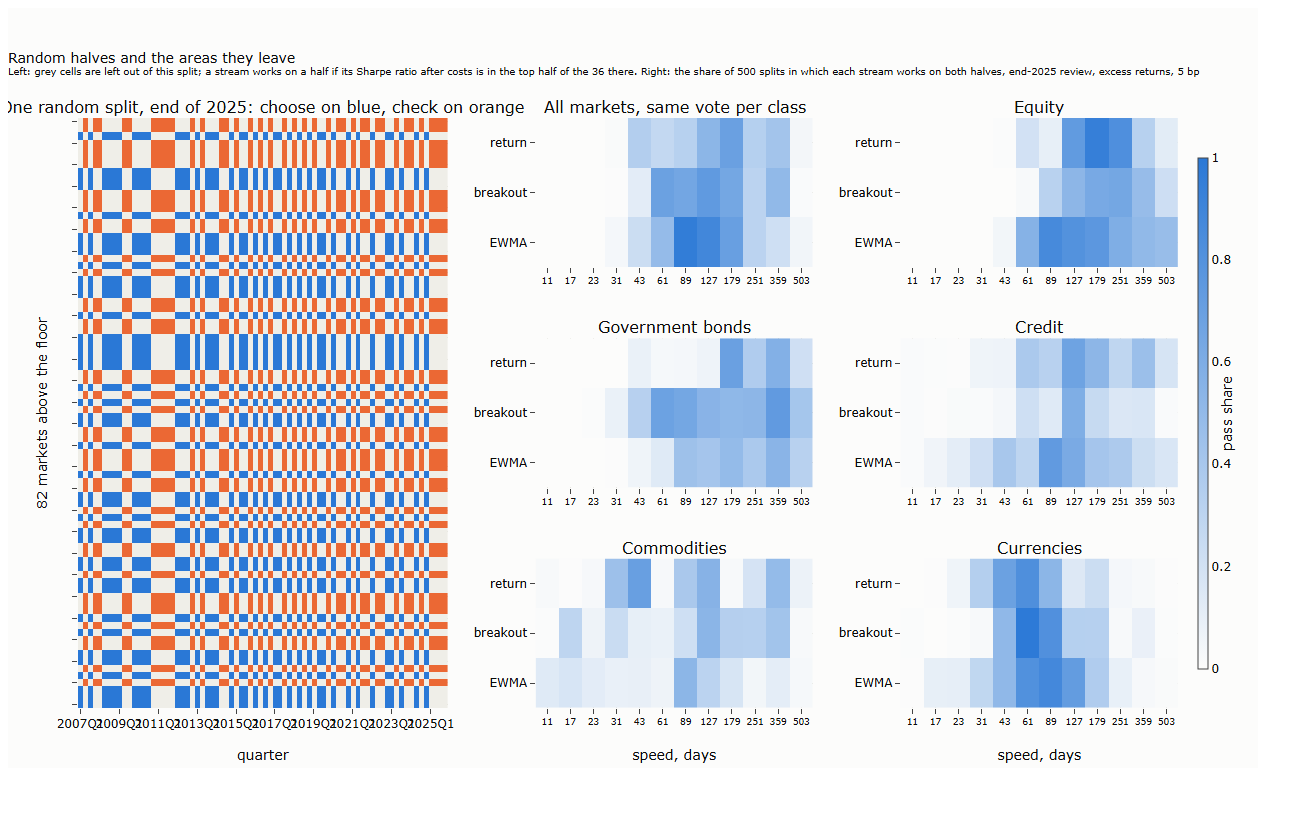

In [9]:
run("l26_charts.py")
pictures("26_halves")

### 3.3 Markets that disagree

SPY and EFA, EWMA crossover at 61 and 359 days, and the blend of every EWMA speed from 43 to 359 days at equal risk, 2007-2026.

In [10]:
band = [f"ewma_{h}" for h in L.SPEEDS if 43 <= h <= 359]
pd.DataFrame({t: {"61 days": L.sharpe(NN[t]["ewma_61"]), "359 days": L.sharpe(NN[t]["ewma_359"]), "blend 43-359": L.sharpe(NN[t][band].div(NN[t][band].std()).mean(axis=1))}
              for t in ("SPY", "EFA")}).T.round(2)

,61 days,359 days,blend 43-359
SPY,0.18,0.56,0.37
EFA,0.16,-0.12,0.03


## 4. The areas and what the rule holds

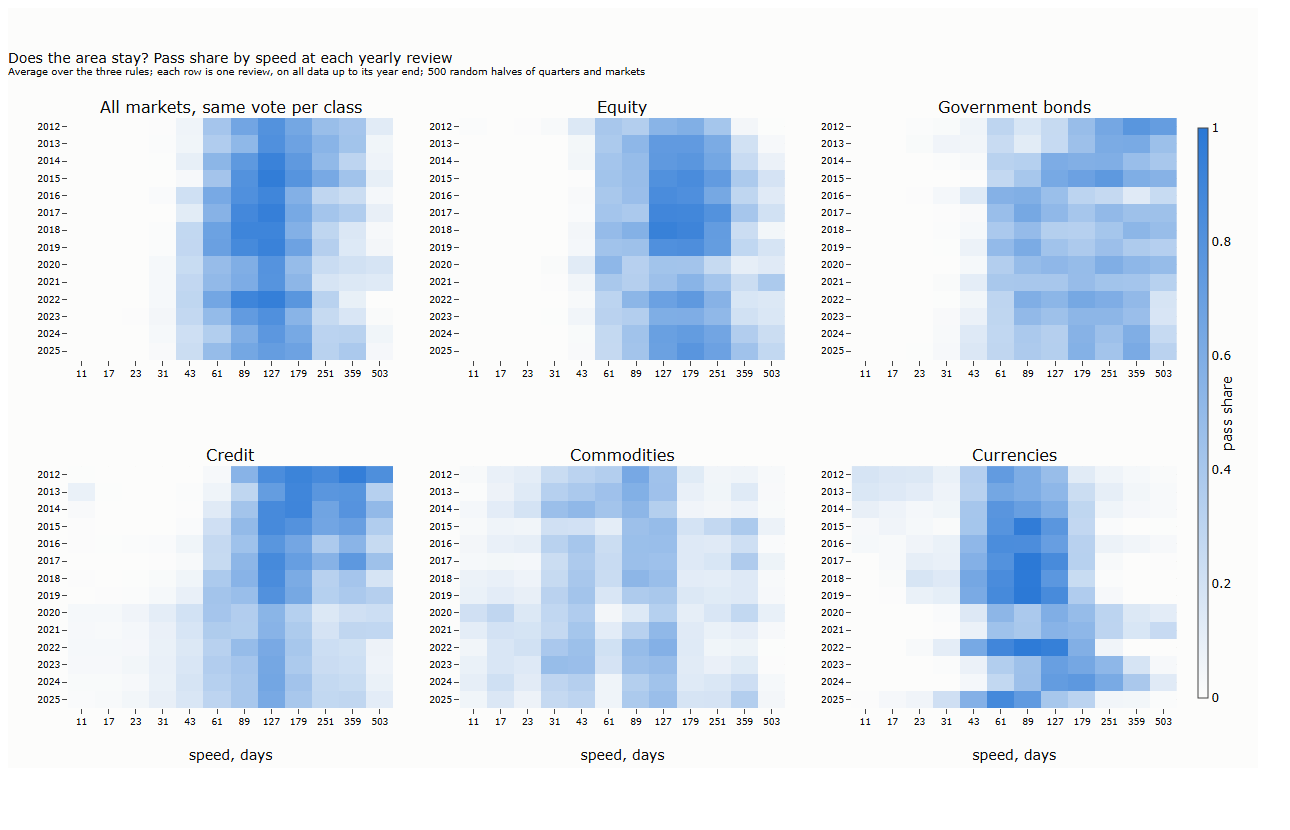

,streams held,kept from the year before,share slower than a year,fastest held
2012,19,NaN,0.37,61
2013,18,0.95,0.33,61
2014,18,0.94,0.28,43
2015,18,0.94,0.33,61
2016,16,0.83,0.19,43
2017,18,1.00,0.28,43
2018,17,0.89,0.18,43
2019,17,1.00,0.18,43
2020,18,0.82,0.22,43
2021,17,0.89,0.12,43


held at every review: ['breakout_61', 'breakout_89', 'breakout_127', 'breakout_179', 'ewma_61', 'ewma_89', 'ewma_127', 'ewma_179', 'ewma_251', 'return_61', 'return_89', 'return_127', 'return_179']


In [11]:
pictures("26_areas")
sel = result("select.json"); held = {y: {k for k, v in r["weights"]["one_set"].items() if v >= 0.2} for y, r in sel["reviews"].items()}; ys = sorted(held)
speed = lambda k: int(k.split("_")[1])
display(pd.DataFrame({"streams held": [len(held[y]) for y in ys], "kept from the year before": [np.nan] + [len(held[a] & held[b]) / len(held[a]) for a, b in zip(ys, ys[1:])],
                      "share slower than a year": [sum(speed(k) >= 251 for k in held[y]) / len(held[y]) for y in ys],
                      "fastest held": [min(map(speed, held[y])) for y in ys]}, index=ys).round(2))
print("held at every review:", sorted(set.intersection(*held.values()), key=lambda k: (k.split("_")[0], speed(k))))

## 5. Super-long speeds in US equity

EWMA crossover at 89, 359 and 503 days, the share of days the 503-day rule is long, and buying and holding (returns over cash), 2007-2026.

In [12]:
rows = {}
for t in ("SPY", "QQQ", "EFA", "EEM", "VGK"):
    c = close[t].dropna(); x, xh, xl = L.excess(c, high[t].reindex(c.index), low[t].reindex(c.index), rf)
    s = L.signals(x.to_frame("x"), xh.to_frame("x"), xl.to_frame("x"), 503)["ewma"]["x"][L.START:].dropna()
    rows[t] = {f"{h} days": L.sharpe(NN[t][f"ewma_{h}"]) for h in (89, 359, 503)} | {"long, 503 days": (s > 0).mean(), "buy and hold": L.sharpe(x.pct_change()[L.START:])}
pd.DataFrame(rows).T.round(2)

,89 days,359 days,503 days,"long, 503 days",buy and hold
SPY,0.26,0.56,0.56,0.90,0.54
QQQ,0.40,0.65,0.62,0.91,0.70
EFA,0.14,-0.12,-0.13,0.73,0.25
EEM,0.07,-0.27,-0.39,0.66,0.24
VGK,0.11,-0.18,-0.10,0.71,0.26


## 6. Out of sample

Table 7.1 and the tests, from the results; then the rule's total Sharpe ratio recomputed from the daily out-of-sample returns.

In [13]:
T = result("tests.json"); names = {"union20": "the rule", "one_set": "weighted by pass share", "class": "per class", "intersection": "intersection", "union": "union", "all36": "all 36"}
tab = pd.DataFrame({names[v]: T["sharpe"][v] | {"worst drawdown": T["drawdown"][v]["total"]} for v in names}).T
display(tab.round(2))
display(pd.DataFrame({f"against {names[v]}": {"difference": T["tests"][f"rule_vs_{v}_total"]["diff"], "band 5%": T["tests"][f"rule_vs_{v}_total"]["ci90"][0],
                                               "band 95%": T["tests"][f"rule_vs_{v}_total"]["ci90"][1]} for v in ("all36", "class", "one_set", "union")}).T.round(2))
print("a class beats the rule after Benjamini-Hochberg:", T["bh_class_beats_rule"])
O = pd.read_parquet(L.OUT / "oos.parquet"); print(f"the rule's total Sharpe ratio from the daily returns: {L.sharpe(O[O.variant == 'union20']['total']):.4f}; results file: {T['sharpe']['union20']['total']:.4f}")

,Equity,Rates,Credit,Commodities,FX,total,worst drawdown
the rule,0.34,0.12,0.02,0.40,0.45,0.49,-0.22
weighted by pass share,0.36,0.10,0.02,0.41,0.44,0.48,-0.23
per class,0.37,0.13,-0.04,0.38,0.41,0.46,-0.23
intersection,0.36,0.05,-0.05,0.54,0.43,0.48,-0.20
union,0.33,0.07,0.02,0.41,0.43,0.46,-0.22
all 36,0.24,-0.13,-0.01,0.42,0.36,0.32,-0.23


,difference,band 5%,band 95%
against all 36,0.16,0.03,0.29
against per class,0.03,-0.05,0.09
against weighted by pass share,0.00,-0.02,0.03
against union,0.03,-0.03,0.08


a class beats the rule after Benjamini-Hochberg: {'Equity': False, 'Rates': False, 'Commodities': False, 'FX': False, 'Credit': False}
the rule's total Sharpe ratio from the daily returns: 0.4862; results file: 0.4862


**Shipped against recomputed.** With `RUN_ALL`, the rerun's key numbers against the shipped results. With the same download they match exactly; a later download can differ slightly, since Yahoo revises adjusted prices when funds pay distributions.

In [14]:
rows = []
for v in ("union20", "class", "all36"):
    rows.append(dict(number=f"Sharpe, {names[v]}", shipped=result("tests.json", SHIPPED)["sharpe"][v]["total"], recomputed=result("tests.json")["sharpe"][v]["total"]))
a, b = result("select.json", SHIPPED)["reviews"]["2025"]["weights"]["one_set"], result("select.json")["reviews"]["2025"]["weights"]["one_set"]
rows.append(dict(number="streams held at the end-2025 review", shipped=sum(v >= 0.2 for v in a.values()), recomputed=sum(v >= 0.2 for v in b.values())))
pd.DataFrame(rows)

,number,shipped,recomputed
0,"Sharpe, the rule",0.486169,0.486169
1,"Sharpe, per class",0.461103,0.461103
2,"Sharpe, all 36",0.324706,0.324706
3,streams held at the end-2025 review,20.000000,20.000000


## 7. A test of your own

Change one setting and see what moves: the 20% bar in `scripts/l26_select.py` (the `union20` line), the volatility window (`L26_VOL_SPAN`, then rebuild the streams), the cost (`COST_BP` in `scripts/l26.py`). Rerun with `RUN_ALL`. Any change made after looking at results should be dated in `results/hypotheses.md` before it is judged on later data, as every change of this lecture was.